# Hawker-centre inspections under uncertain visit durations
**DBA5103 · Extension 3 · West Coast–Jurong West**

**How many stalls can one team cover and still get back to its depot within eight hours if inspections take longer than planned?** Extension 2 lets the team choose centres and assumes 60 minutes per visit. We keep its routing decisions and coverage objective. We first allow visit time to depend on centre size (3A), then reserve time for delays using Lecture 5 (3B). We evaluate the resulting routes under simulated delays (3C) and test how the assumed size effect changes the decision (3D).

The main comparison uses **480 available minutes** throughout. A final **300-minute comparison** reproduces the worked example from Extension 2 and the earlier Extension 3 guide. A stall counts towards coverage when its centre is visited. The data record centre size, so the objective measures the reach of the selected visits. It cannot identify which individual stalls the team inspects.

**Running the notebook.** In Jupyter, run the cells from top to bottom with Python 3, NumPy, pandas and Matplotlib. Gurobi solves the mixed-integer model when available. An exact seven-centre enumeration also works on its own. The code reads the project CSVs when run in the repository root or its `src` directory. An embedded copy of the same inputs lets you run the downloaded notebook on its own.

All numerical examples in the discussion refer to the default settings and the included project data.

## Inputs and workday assumptions

| Input | Source or modelling choice |
|---|---|
| Centre locations, cooked-food stall counts and node IDs | Team’s processed `nodes.csv`. Node 0 is the **Boon Lay Office, 325 Boon Lay Place**, the depot in the processed dataset. Nodes 1–7 are hawker centres. |
| Travel minutes $c_{ij}$ | Team’s `time_matrix_min.csv`, with **row = from** and **column = to**. OSRM estimates are for driving in free-flow conditions. Direction matters. |
| Workday $T$ | One depot-to-depot trip. Travel, service and the return journey count. As agreed with Extensions 1 and 2, we model no separate lunch break or midday closure. We keep free-flow travel fixed to isolate inspection uncertainty. |
| Service times and delays | Scenario assumptions. The dataset contains no measured inspection durations. The values of $b$, $\delta$ and the simulation distribution can be changed. |

In [1]:
from pathlib import Path
from io import StringIO
from itertools import combinations, permutations
from math import factorial, floor, prod

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import gurobipy as gp
    from gurobipy import GRB
except ImportError:
    gp = None

DAY = 480
BASE_SLOPE = 0.5
DELAY_SHARE = 0.30
GAMMAS = tuple(range(8))
DRAWS = 10_000
SEED = 5103
SLOPES = tuple(sorted({0.0, BASE_SLOPE, 1.0}))

In [2]:
# Snapshot of the two project inputs used by this model.
NODE_CSV = """node_id,type,short_name,cooked_food_stalls
0,depot,Depot - Town Council (Boon Lay),0
1,hawker,Jurong West Hawker Centre,39
2,hawker,Boon Lay Place Market and Food Village,72
3,hawker,Jurong West Street 52 Blk 505,60
4,hawker,Taman Jurong Market and Food Centre,122
5,hawker,Teban Gardens Market and Food Centre,28
6,hawker,Ayer Rajah Food Centre,80
7,hawker,Clementi West Street 2 Blk 726,60
"""

TRAVEL_CSV = r"""from\to,0,1,2,3,4,5,6,7
0,0.0,4.94,1.61,3.75,4.03,9.52,11.59,12.76
1,5.28,0.0,5.51,5.95,6.69,11.35,13.42,14.33
2,2.66,5.33,0.0,4.56,5.86,11.34,13.42,14.58
3,4.82,6.18,5.54,0.0,5.6,9.53,11.6,12.77
4,4.62,6.08,4.39,5.41,0.0,7.46,9.53,10.44
5,9.41,10.5,9.18,8.72,7.46,0.0,5.29,6.45
6,11.77,12.14,11.54,11.08,9.11,5.81,0.0,3.61
7,12.9,13.28,12.68,12.22,10.24,6.94,3.48,0.0
"""

In [3]:
def read_project_data():
    folders = [Path("data/processed"), Path("../data/processed")]
    for folder in folders:
        node_file = folder / "nodes.csv"
        matrix_file = folder / "time_matrix_min.csv"
        if node_file.exists() or matrix_file.exists():
            return (pd.read_csv(node_file), pd.read_csv(matrix_file, index_col=0),
                    f"Project CSVs in {folder}")
    return (pd.read_csv(StringIO(NODE_CSV)), pd.read_csv(StringIO(TRAVEL_CSV), index_col=0),
            "Embedded copy of the project CSV inputs")


nodes, matrix, source = read_project_data()
nodes = nodes.sort_values("node_id").set_index("node_id")
matrix.index = matrix.index.astype(int)
matrix.columns = matrix.columns.astype(int)
V = tuple(nodes.index)
H = V[1:]
assert V == tuple(range(8)) and nodes.loc[0, "type"] == "depot"
assert matrix.shape == (8, 8) and set(matrix.index) == set(matrix.columns) == set(V)
assert nodes.loc[list(H), "type"].eq("hawker").all()
travel = matrix.loc[list(V), list(V)].to_numpy(dtype=float)
w = nodes.cooked_food_stalls.to_numpy(dtype=float)
assert np.isfinite(travel).all() and (travel >= 0).all() and np.allclose(travel.diagonal(), 0)
assert np.isfinite(w).all() and (w >= 0).all() and np.all(w == np.floor(w)) and w[0] == 0
print(source)
display(nodes[["short_name", "cooked_food_stalls"]].rename(
    columns={"short_name": "Centre / depot", "cooked_food_stalls": "Cooked-food stalls"}))

Project CSVs in ../data/processed


,Centre / depot,Cooked-food stalls
node_id,,
0,Depot - Town Council (Boon Lay),0
1,Jurong West Hawker Centre,39
2,Boon Lay Place Market and Food Village,72
3,Jurong West Street 52 Blk 505,60
4,Taman Jurong Market and Food Centre,122
5,Teban Gardens Market and Food Centre,28
6,Ayer Rajah Food Centre,80
7,Clementi West Street 2 Blk 726,60


## 3A · Let larger centres take longer

Among the seven centres, the median stall count is 60. We anchor a 60-stall centre at Extension 2's 60 minutes and let $b$ be the **extra team minutes per additional stall**. For any hawker centre $i$ with $w_i$ stalls,

$$\bar t_i=60+b(w_i-60)=60(1-b)+bw_i,\qquad 0\le b\le1.$$

At $b=0$ each visit takes 60 minutes. At $b=0.5$ we assume 30 minutes of common work plus half a team-minute per stall. At $b=1$ we allow one team-minute per stall. We set both nominal duration and delay allowance to zero at the depot. The 60-stall anchor comes from the data. The slope and fixed component are modelling choices.

**Routing decisions.** Let $V=\{0,\ldots,7\}$, $H=V\setminus\{0\}$ and $A=\{(i,j)\in V^2:i\ne j\}$. Binary $x_{ij}$ selects a road journey, binary $y_i$ selects a visit, and continuous $u_i$ orders the selected centres. We first maximise $\sum_{i\in H}w_i y_i$. Among all coverage-optimal feasible plans, we minimise $C(x)=\sum_{(i,j)\in A}c_{ij}x_{ij}$. This gives a reproducible travel criterion when several plans cover the same number of stalls.

$$
\begin{aligned}
\sum_{j:(i,j)\in A}x_{ij} &= y_i, &
\sum_{j:(j,i)\in A}x_{ji} &= y_i &&(i\in V),\\
y_0 &= 1, & u_0 &= 0,\\
y_i &\le u_i\le 7y_i &&& (i\in H),\\
u_i+1-u_j &\le 8(1-x_{ij}) &&& ((i,j)\in A,\ j\in H),\\
C(x)+\sum_{i\in H}\bar t_i y_i &\le T.&&&
\end{aligned}
$$

Every visited node has one incoming and one outgoing journey. The order increases on selected journeys into a centre, which rules out disconnected cycles. This formulation requires the team to visit at least one centre and return. Section 3B changes only the final time constraint.

In [4]:
def duration_inputs(b, delay_share):
    if not 0 <= b <= 1 or delay_share < 0:
        raise ValueError("Use b between 0 and 1 and a nonnegative delay share.")
    nominal = np.zeros(len(V))
    nominal[1:] = 60 + b * (w[1:] - 60)
    return nominal, delay_share * nominal


nominal, deviations = duration_inputs(BASE_SLOPE, DELAY_SHARE)
inputs = pd.DataFrame({"Centre": nodes.short_name, "Stalls": w.astype(int),
                       "Nominal min": nominal, "Max delay min": deviations,
                       "Upper duration min": nominal + deviations})
display(inputs.round(2))

,Centre,Stalls,Nominal min,Max delay min,Upper duration min
node_id,,,,,
0,Depot - Town Council (Boon Lay),0,0.0,0.00,0.00
1,Jurong West Hawker Centre,39,49.5,14.85,64.35
2,Boon Lay Place Market and Food Village,72,66.0,19.80,85.80
3,Jurong West Street 52 Blk 505,60,60.0,18.00,78.00
4,Taman Jurong Market and Food Centre,122,91.0,27.30,118.30
5,Teban Gardens Market and Food Centre,28,44.0,13.20,57.20
6,Ayer Rajah Food Centre,80,70.0,21.00,91.00
7,Clementi West Street 2 Blk 726,60,60.0,18.00,78.00


### Centre size and inspection time

The three lines compare Extension 2's fixed duration with two size-based rules. The dots mark the stall counts in the project data. Their heights come from the assumed formulas.

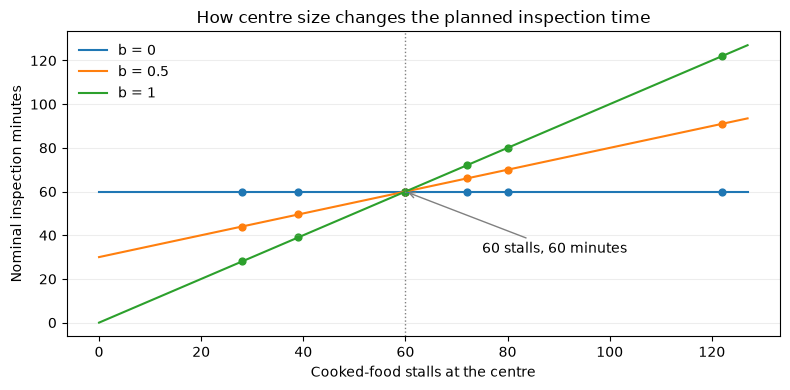

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sizes = np.linspace(0, max(w) + 5, 180)
for b in SLOPES:
    line, = ax.plot(sizes, 60 + b * (sizes - 60), label=f"b = {b:g}")
    centre_times, _ = duration_inputs(b, 0.0)
    ax.scatter(w[1:], centre_times[1:], color=line.get_color(), s=24)
ax.axvline(60, color="grey", linestyle=":", linewidth=1)
ax.annotate("60 stalls, 60 minutes", xy=(60, 60), xytext=(75, 32),
            arrowprops={"arrowstyle": "->", "color": "grey"})
ax.set(xlabel="Cooked-food stalls at the centre", ylabel="Nominal inspection minutes",
       title="How centre size changes the planned inspection time")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.22)
fig.tight_layout()
plt.show()

### How does a longer workday change coverage?

We check every depot-return visiting order and keep the shortest tour for each of the 127 nonempty sets of centres. All orders through a given set have the same service time. This lets us solve each of the 600 whole-minute workday limits from 0 to 599 exactly. Each plan maximises coverage first and minimises driving time second. Blank values identify limits too short for even one visit and a return.

In [6]:
def drive_time(route):
    return float(sum(travel[i, j] for i, j in zip(route, route[1:])))


def build_catalogue():
    catalogue = []
    for size in range(1, len(H) + 1):
        for subset in combinations(H, size):
            tours = ((0, *order, 0) for order in permutations(subset))
            minutes, tour = min((round(drive_time(route), 9), route) for route in tours)
            catalogue.append((subset, tour, minutes, int(w[list(subset)].sum())))
    return catalogue


catalogue = build_catalogue()
print(f"{len(catalogue)} nonempty subsets, "
      f"{sum(factorial(7) // factorial(7 - k) for k in range(1, 8)):,} directed tours checked.")

127 nonempty subsets, 13,699 directed tours checked.


In [7]:
def nominal_sweep(b):
    mu, _ = duration_inputs(b, 0.0)
    options = []
    for subset, route, driving, stalls in catalogue:
        used = driving + mu[list(subset)].sum()
        options.append((stalls, driving, route, used))
    options.sort(key=lambda p: (-p[0], p[1], p[2]))

    rows = []
    for limit in range(600):
        feasible = next((p for p in options if p[3] <= limit + 1e-8), None)
        if feasible is None:
            rows.append((b, limit, np.nan, np.nan, None))
        else:
            stalls, _, route, used = feasible
            rows.append((b, limit, stalls, used, " → ".join(map(str, route))))
    return rows


sweep = pd.DataFrame([row for b in SLOPES for row in nominal_sweep(b)],
                     columns=["b", "Available min", "Stalls", "Time used", "Route"])
sweep["Stalls"] = sweep["Stalls"].astype("Int64")
baseline_sweep = sweep[sweep["b"].eq(BASE_SLOPE)]
display(baseline_sweep[baseline_sweep["Available min"].isin([300, 400, DAY, 500])]
        .drop(columns="b").set_index("Available min").round(2))

minimum_all = sweep[sweep["Stalls"].eq(int(w.sum()))].groupby("b")["Available min"].min()
display(minimum_all.rename("First whole-minute limit covering all seven centres").to_frame())

,Stalls,Time used,Route
Available min,,,
300,293,289.61,0 → 2 → 1 → 3 → 4 → 0
400,394,383.15,0 → 2 → 3 → 7 → 6 → 4 → 0
480,433,439.37,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
500,461,486.58,0 → 2 → 1 → 3 → 5 → 7 → 6 → 4 → 0


,First whole-minute limit covering all seven centres
b,
0.0,467
0.5,487
1.0,508


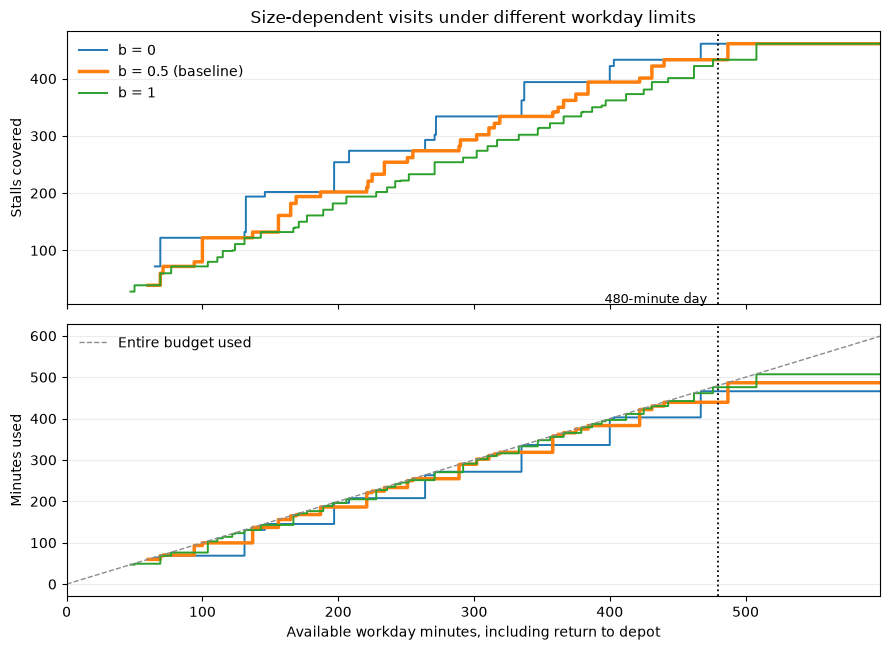

In [8]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6.6))
for b, group in sweep.groupby("b"):
    group = group.dropna(subset=["Stalls"])
    width = 2.5 if b == BASE_SLOPE else 1.4
    label = f"b = {b:g}" + (" (baseline)" if b == BASE_SLOPE else "")
    axes[0].step(group["Available min"], group["Stalls"].astype(int),
                 where="post", linewidth=width, label=label)
    axes[1].step(group["Available min"], group["Time used"], where="post", linewidth=width)
axes[1].plot([0, 599], [0, 599], "--", color="0.55", linewidth=1, label="Entire budget used")
for ax in axes:
    ax.axvline(DAY, linestyle=":", color="black", linewidth=1.3)
    ax.grid(axis="y", alpha=0.24)
    ax.set_xlim(0, 599)
axes[0].set(title="Size-dependent visits under different workday limits", ylabel="Stalls covered")
axes[0].legend(frameon=False, loc="upper left")
axes[0].text(DAY - 8, 8, f"{DAY}-minute day", ha="right", fontsize=9)
axes[1].set(xlabel="Available workday minutes, including return to depot", ylabel="Minutes used")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

With the baseline size rule, the 480-minute day reaches **433 of 461 stalls** across six centres. The shortest tour of all seven needs 46.08 minutes of driving and 440.50 minutes of inspections. Its total is **486.58 minutes**, so **487** is the first whole-minute budget that covers all seven. At 480 minutes, the team omits Teban Gardens (28 stalls) and returns after **439.37 minutes**. Section 3B asks how much of that spare time would be needed if visits ran late.

## 3B · Protect the return time using Lecture 5

The team chooses its route before seeing any delays. Let the actual service time be $\tilde t_i=\bar t_i+d_i z_i$, with an assumed maximum extra time $d_i=\delta\bar t_i$ and baseline $\delta=0.30$. A delay uses a fraction $z_i$ of its centre's allowance. The uncertainty set is

$$\mathcal U(\Gamma)=\left\{z:0\le z_i\le1,\;\sum_{i\in H}z_i\le\Gamma\right\},\quad 0\le\Gamma\le7.$$

Lecture 5's pharmaceutical example limits the sum of two absolute deviations to $2\alpha$. Here only upward deviations use up workday capacity, so $z_i$ can be taken as nonnegative. With seven centres, the analogous normalised budget is $\Gamma=7\alpha$. A budget of 1 protects against **one full delay or any combination of partial delays totalling one**. A budget of 7 allows all seven maximum delays together. Choosing $\Gamma$ specifies the scenarios the route must withstand. A probability estimate requires a separate assumption, introduced in 3C.

**From the inner LP to a linear time constraint.** For fixed visits $y$, the largest additional service time is $R_\Gamma(y)=\max_{z\in\mathcal U(\Gamma)}\sum_i d_i y_i z_i$. Give the joint budget a dual variable $\pi\ge0$ and each upper bound $z_i\le1$ a dual variable $\rho_i\ge0$. LP duality gives

$$R_\Gamma(y)=\min_{\pi,\rho\ge0}\left\{\Gamma\pi+\sum_{i\in H}\rho_i:\ \pi+\rho_i\ge d_i y_i\quad(i\in H)\right\}.$$

The inner LP is feasible and bounded. Its dual has the same optimal value, so the following two linear rows enforce the time limit for every allowed delay pattern:

$$C(x)+\sum_{i\in H}\bar t_i y_i+\Gamma\pi+\sum_{i\in H}\rho_i\le T,\qquad
\pi+\rho_i\ge d_i y_i\quad(i\in H),\quad \pi,\rho_i\ge0.$$

For integer $\Gamma$, the exact reserve is the sum of the largest $\Gamma$ selected delay bounds, capped at the number of visits. A fractional budget also includes the corresponding fraction of the next largest delay. We report this tight reserve directly because the routing objective can leave slack in the dual variables.

### Solving and checking the model

The two methods below use the same priorities. Gurobi solves the robust mixed-integer formulation. With seven centres we can also check every nonempty subset and visiting order. For a fixed subset, service time and delay allowance stay the same in every order, so we retain its shortest directed depot tour. Enumeration verifies optimal coverage and the travel tie-break for each case.

In [9]:
def tight_reserve(bounds, gamma):
    ordered = sorted(bounds, reverse=True)
    count = min(gamma, len(ordered))
    full = floor(count)
    fraction = count - full
    return sum(ordered[:full]) + (fraction * ordered[full] if full < len(ordered) else 0.0)


def enumerate_optimum(mu, dev, gamma, limit):
    candidates = []
    for subset, route, minutes, coverage in catalogue:
        selected = list(subset)
        total = minutes + mu[selected].sum() + tight_reserve(dev[selected], gamma)
        if total <= limit + 1e-8:
            candidates.append((-coverage, minutes, route))
    return min(candidates)[2] if candidates else None

In [10]:
def mip_route(env, mu, dev, gamma, limit):
    arcs = [(i, j) for i in V for j in V if i != j]
    with gp.Model("robust_hawker_visits", env=env) as model:
        model.Params.MIPGap = 0
        model.Params.MIPGapAbs = 0
        x = model.addVars(arcs, vtype=GRB.BINARY, name="arc")
        y = model.addVars(V, vtype=GRB.BINARY, name="visit")
        u = model.addVars(V, lb=0, name="order")
        pi = model.addVar(lb=0, name="pi")
        rho = model.addVars(H, lb=0, name="rho")

        model.addConstr(y[0] == 1)
        model.addConstr(u[0] == 0)
        for i in V:
            model.addConstr(x.sum(i, "*") == y[i])
            model.addConstr(x.sum("*", i) == y[i])
        for i in H:
            model.addConstr(y[i] <= u[i])
            model.addConstr(u[i] <= len(H) * y[i])
        for i, j in arcs:
            if j != 0:
                model.addConstr(u[i] + 1 - u[j] <= len(V) * (1 - x[i, j]))

        driving = gp.quicksum(travel[i, j] * x[i, j] for i, j in arcs)
        service = gp.quicksum(mu[i] * y[i] for i in H)
        for i in H:
            model.addConstr(pi + rho[i] >= dev[i] * y[i])
        model.addConstr(driving + service + gamma * pi + rho.sum() <= limit)

        coverage = gp.quicksum(w[i] * y[i] for i in H)
        model.ModelSense = GRB.MAXIMIZE
        model.setObjectiveN(coverage, 0, priority=2, abstol=0, reltol=0)
        model.setObjectiveN(-driving, 1, priority=1, abstol=0, reltol=0)
        model.optimize()
        if model.Status == GRB.INFEASIBLE:
            return None
        if model.Status != GRB.OPTIMAL:
            raise RuntimeError(f"Gurobi status {model.Status}. Optimality unconfirmed.")

        successor = {i: j for i, j in arcs if x[i, j].X > 0.5}
        selected = {i for i in H if y[i].X > 0.5}
        route = [0]
        for _ in V:
            route.append(successor[route[-1]])
            if route[-1] == 0:
                break
        assert route[-1] == 0 and len(route) == len(selected) + 2
        assert set(route[1:-1]) == selected
        return tuple(route)

In [11]:
env = None
if gp is not None:
    try:
        env = gp.Env(empty=True)
        env.setParam("OutputFlag", 0)
        env.setParam("Threads", 1)
        env.start()
    except gp.GurobiError as error:
        if error.errno != gp.GRB.Error.NO_LICENSE:
            raise
        env.dispose()
        env = None
print("Solver: Gurobi, cross-checked by enumeration." if env is not None
      else "Solver: exact enumeration of all tours.")


def solve_case(b, delay_share, gamma, limit):
    if not 0 <= gamma <= len(H):
        raise ValueError("The uncertainty budget must lie between 0 and 7.")
    mu, dev = duration_inputs(b, delay_share)
    route = enumerate_optimum(mu, dev, gamma, limit)
    if env is not None:
        mip = mip_route(env, mu, dev, gamma, limit)
        assert (mip is None) == (route is None)
        if mip is not None:
            assert w[list(mip[1:-1])].sum() == w[list(route[1:-1])].sum()
            assert np.isclose(drive_time(mip), drive_time(route), atol=1e-6, rtol=0)
            route = mip
    if route is None:
        raise ValueError(f"No depot tour fits the selected scenario (T={limit}, Γ={gamma}).")
    selected = list(route[1:-1])
    driving = drive_time(route)
    service = float(mu[selected].sum())
    reserve = tight_reserve(dev[selected], gamma)
    protected = driving + service + reserve
    assert protected <= limit + 1e-6
    return {"b": b, "Γ": gamma, "Route": " → ".join(map(str, route)), "Stops": len(selected),
            "Stalls": int(w[selected].sum()), "Drive": driving, "Service": service,
            "Nominal": driving + service, "Reserve": reserve, "Protected": protected,
            "All delays": driving + service + dev[selected].sum(), "Selected": selected}

Solver: Gurobi, cross-checked by enumeration.


### Routes at different protection levels

The main comparison varies $\Gamma$ from 0 to 7. We also evaluate $\alpha=0,0.1,\ldots,1$ using $\Gamma=7\alpha$, so the two sets of results can be compared at the same protection level. All time columns are minutes. **Nominal** includes driving, visits and the return. **Protected** adds the worst delay allowed by the chosen budget. **All delays** allows every selected visit to reach its upper bound.

In [12]:
alpha_budgets = np.round(len(H) * np.linspace(0, 1, 11), 8)
budgets = sorted(set(GAMMAS).union(alpha_budgets))
cases = pd.DataFrame([solve_case(b, DELAY_SHARE, g, DAY) for b in SLOPES for g in budgets])
base_all = cases[cases["b"].eq(BASE_SLOPE)].set_index("Γ").sort_index()
base = base_all.loc[list(GAMMAS)].copy()
base["α"] = base.index.to_numpy() / len(H)
display(base[["α", "Stops", "Stalls", "Drive", "Service", "Nominal", "Reserve", "Protected",
              "All delays", "Route"]].round(2))

# Both models must recover the size-dependent 3A result at zero protection.
zero_delay = cases[cases["Γ"].eq(0)].set_index("b")
for b in SLOPES:
    match = sweep[sweep["b"].eq(b) & sweep["Available min"].eq(DAY)]
    if not match.empty:
        assert zero_delay.loc[b, "Stalls"] == match.iloc[0]["Stalls"]
        assert np.isclose(zero_delay.loc[b, "Nominal"], match.iloc[0]["Time used"])

,α,Stops,Stalls,Drive,Service,Nominal,Reserve,Protected,All delays,Route
Γ,,,,,,,,,,
0.0,0.00,6,433,42.87,396.5,439.37,0.00,439.37,558.32,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
1.0,0.14,6,433,42.87,396.5,439.37,27.30,466.67,558.32,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
2.0,0.29,6,422,39.36,391.0,430.36,48.30,478.66,547.66,0 → 2 → 3 → 5 → 7 → 6 → 4 → 0
3.0,0.43,5,394,36.15,347.0,383.15,68.10,451.25,487.25,0 → 2 → 3 → 7 → 6 → 4 → 0
4.0,0.57,5,394,36.15,347.0,383.15,86.10,469.25,487.25,0 → 2 → 3 → 7 → 6 → 4 → 0
5.0,0.71,5,373,38.22,336.5,374.72,100.95,475.67,475.67,0 → 2 → 1 → 3 → 6 → 4 → 0
6.0,0.86,5,373,38.22,336.5,374.72,100.95,475.67,475.67,0 → 2 → 1 → 3 → 6 → 4 → 0
7.0,1.00,5,373,38.22,336.5,374.72,100.95,475.67,475.67,0 → 2 → 1 → 3 → 6 → 4 → 0


At $\Gamma=1$ the six-centre plan still fits after allowing 27.30 minutes for Taman Jurong. At $\Gamma=2$ it would take $439.37+27.30+21.00=487.67$ minutes. Exchanging Jurong West Hawker Centre (39 stalls) for Teban Gardens (28 stalls) brings protected time down to **478.66 minutes** and coverage to **422 stalls**.

The $\alpha=0.3$ calculation uses $\Gamma=2.1$. At that budget the 422-stall plan would need an additional $0.1\times19.8=1.98$ minutes, taking it to **480.64**. Re-optimising gives **401 stalls**. This change over a tenth of a budget unit explains the difference between the two grids.

### Worked example from Lecture 5's protection scale

At $\alpha=0.5$ the team plans for $\Gamma=3.5$ full-delay equivalents across the seven centres. On the selected 394-stall route, the delay bounds in descending order are 27.30, 21.00, 19.80, 18.00 and 18.00 minutes. The **required reserve** is $27.30+21.00+19.80+0.5(18.00)=77.10$ minutes. The **available time above the nominal schedule** is $480-383.15=96.85$ minutes. After providing the required reserve the team still has **19.75 minutes** left.

In [13]:
worked = base_all.loc[0.5 * len(H)]
example_times = pd.Series({
    "Nominal depot-to-depot time": worked["Nominal"],
    "Available time above nominal": DAY - worked["Nominal"],
    "Required delay reserve": worked["Reserve"],
    "Protected depot-to-depot time": worked["Protected"],
    "Time remaining after protection": DAY - worked["Protected"],
}, name="Minutes")
display(example_times.round(2).to_frame())

,Minutes
Nominal depot-to-depot time,383.15
Available time above nominal,96.85
Required delay reserve,77.10
Protected depot-to-depot time,460.25
Time remaining after protection,19.75


## 3C · How often does each fixed route run over?

We simulate 10,000 workdays, drawing each centre's delay independently from $\mathrm{Uniform}(0,d_i)$. The team completes its selected route on each day. All routes face the **same simulated workdays**, so identical routes receive identical results. The draws can fall outside $\mathcal U(\Gamma)$, which lets us measure what happens beyond the protected scenarios. Overtime means total duration strictly exceeds 480 minutes.

A simulation may produce zero overruns for a route that can still finish late. We therefore also compute the exact exceedance probability **under the same assumed independent uniforms**. For positive bounds $d_1,\ldots,d_k$, the CDF of their summed delays is
$$ F(s)=\frac{1}{k!\prod_i d_i}\sum_{S\subseteq\{1,\ldots,k\}}(-1)^{|S|}\left(s-\sum_{i\in S}d_i\right)_+^k. $$
The delays' joint uniform density makes this the volume of the box below the time threshold, divided by the box volume. The full-delay upper bound in the results table gives a separate, distribution-free check.

In [14]:
def exact_overtime(bounds, planned, limit):
    widths = [float(d) for d in bounds if d > 0]
    slack = limit - planned
    total = sum(widths)
    if not widths:
        return float(planned > limit)
    if slack <= 0:
        return 1.0
    if slack >= total:
        return 0.0

    # Symmetry lets us evaluate the smaller tail directly for very rare overruns.
    def lower_tail(s):
        k = len(widths)
        volume = 0.0
        for size in range(k + 1):
            for subset in combinations(widths, size):
                volume += (-1)**size * max(s - sum(subset), 0.0)**k
        return volume / (factorial(k) * prod(widths))

    if slack >= total / 2:
        return lower_tail(total - slack)
    return 1.0 - lower_tail(slack)


rng = np.random.default_rng(SEED)
shocks = rng.uniform(size=(DRAWS, len(H)))
risk_rows = []
risk_budgets = sorted(set(GAMMAS).union([round(0.3 * len(H), 8), 0.5 * len(H)]))
for g, plan in base_all.loc[risk_budgets].iterrows():
    ids = np.array(sorted(plan["Selected"]), dtype=int)
    bounds = deviations[ids]
    totals = plan["Nominal"] + shocks[:, ids - 1] @ bounds
    overruns = np.count_nonzero(totals > DAY)
    risk_rows.append({"Γ": g, "Stalls": plan["Stalls"], "Mean actual min": totals.mean(),
                      f"Overruns / {DRAWS:,}": overruns, "Simulated %": 100 * overruns / DRAWS,
                      "Exact %": 100 * exact_overtime(bounds, plan["Nominal"], DAY),
                      "All delays min": plan["All delays"]})
risk = pd.DataFrame(risk_rows).set_index("Γ")
display(risk.round({"Mean actual min": 2, "Simulated %": 2, "Exact %": 5, "All delays min": 2}))

,Stalls,Mean actual min,"Overruns / 10,000",Simulated %,Exact %,All delays min
Γ,,,,,,
0.0,433,498.67,9008,90.08,90.35572,558.32
1.0,433,498.67,9008,90.08,90.35572,558.32
2.0,422,488.82,7254,72.54,73.21836,547.66
2.1,401,478.86,4674,46.74,47.25610,536.09
3.0,394,435.00,0,0.00,0.00454,487.25
3.5,394,435.00,0,0.00,0.00454,487.25
4.0,394,435.00,0,0.00,0.00454,487.25
5.0,373,425.03,0,0.00,0.00000,475.67
6.0,373,425.03,0,0.00,0.00000,475.67


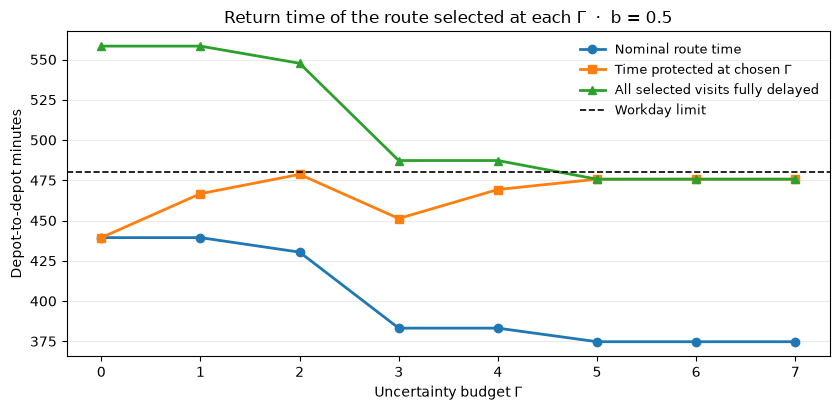

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for column, marker, label in [("Nominal", "o", "Nominal route time"),
                              ("Protected", "s", "Time protected at chosen Γ"),
                              ("All delays", "^", "All selected visits fully delayed")]:
    ax.plot(base.index, base[column], marker=marker, linewidth=2, label=label)
ax.axhline(DAY, color="black", linestyle="--", linewidth=1.2, label="Workday limit")
ax.set(xlabel="Uncertainty budget Γ", ylabel="Depot-to-depot minutes", xticks=GAMMAS,
       title=f"Return time of the route selected at each Γ  ·  b = {BASE_SLOPE:g}")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**The 394-stall decision.** $\Gamma=3$ and $\Gamma=4$ select exactly the same route, so the route has the same physical overtime risk under either label. Its all-delay time is **487.25 minutes**. Under the independent uniform assumption, the probability of exceeding 480 minutes is approximately **0.00454%** (about 1 in 22,000 simulated-model days). Positive correlation or a different delay distribution could change that estimate.

**If the return deadline is strict**, the 373-stall route at $\Gamma=5$ fits even when all five selected visits reach their upper bounds. It takes at most **475.67 minutes**, leaving **4.33 minutes** under the model. The choice between these two routes is concrete: covering **21 additional stalls** admits up to **7.25 minutes of overtime**. Both conclusions depend on the assumed service bounds and fixed travel estimates.

## 3D · How much depends on the assumed inspection-time slope?

Keep $T=480$ and $\delta=30\%$ fixed. Each cell gives optimal stall coverage for one size slope and one uncertainty budget. Compare across a row to isolate protection. Compare down a column to see the effect of the size rule. Changing $b$ also changes total nominal service across the seven centres because their average stall count exceeds the 60-stall anchor.

Γ,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0
b,,,,,,,,
0.0,461,433,433,433,433,394,394,394
0.5,433,433,422,394,394,373,373,373
1.0,433,401,373,362,342,339,334,334


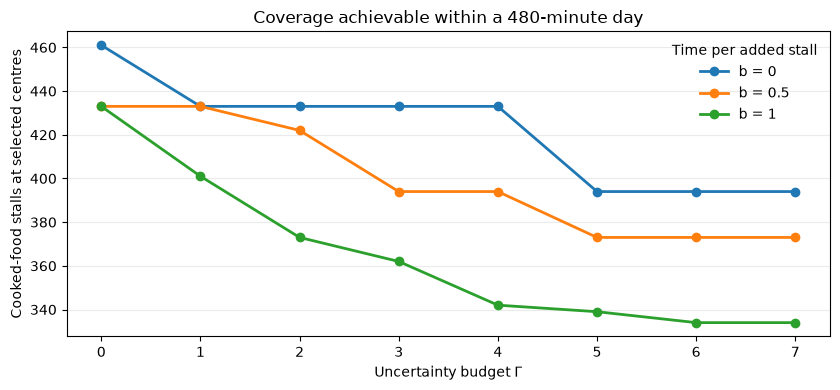

In [16]:
grid = cases[cases["Γ"].isin(GAMMAS)].pivot(index="b", columns="Γ", values="Stalls")
display(grid)
fig, ax = plt.subplots(figsize=(8.5, 4))
for b, row in grid.iterrows():
    ax.plot(row.index, row.values, marker="o", linewidth=2, label=f"b = {b:g}")
ax.set(xlabel="Uncertainty budget Γ", ylabel="Cooked-food stalls at selected centres",
       title="Coverage achievable within a 480-minute day", xticks=GAMMAS)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Time per added stall", frameon=False)
fig.tight_layout()
plt.show()

The same sensitivity calculation on the $\alpha$ grid gives the following table. Each entry is the optimal number of stalls at visited centres.

In [17]:
alpha_view = cases[cases["Γ"].isin(alpha_budgets)].pivot(index="Γ", columns="b", values="Stalls")
alpha_view.insert(0, "α", np.round(alpha_view.index.to_numpy() / len(H), 1))
display(alpha_view.reset_index().set_index(["α", "Γ"]))

,b,0.0,0.5,1.0
α,Γ,,,
0.0,0.0,461,433,433
0.1,0.7,461,433,401
0.2,1.4,433,433,394
0.3,2.1,433,401,373
0.4,2.8,433,394,362
0.5,3.5,433,394,353
0.6,4.2,433,394,342
0.7,4.9,394,373,341
0.8,5.6,394,373,334


At $b=0.5$, moving from nominal planning to protection against all delays reduces coverage by **60 stalls** (433 to 373). The same comparison costs **67 stalls** at $b=0$ and **99 stalls** at $b=1$. The one-minute-per-stall case has the largest loss. The three slopes do **not** establish a steadily increasing loss as $b$ rises.

The delay cap is also an assumption. The next table varies it while holding the baseline slope fixed and reports coverage at no protection, intermediate protection and full protection. Inspection start and end times from future field visits could help estimate both the size relationship and a defensible upper delay.

In [18]:
cap_rows = []
for share in (0.15, DELAY_SHARE, 0.45):
    for g in (0, 3, 7):
        stalls = (base.loc[g, "Stalls"] if share == DELAY_SHARE
                  else solve_case(BASE_SLOPE, share, g, DAY)["Stalls"])
        cap_rows.append({"Maximum delay": f"{share:.0%} of nominal", "Γ": g, "Stalls": stalls})
display(pd.DataFrame(cap_rows).pivot(index="Maximum delay", columns="Γ", values="Stalls"))

Γ,0,3,7
Maximum delay,,,
15% of nominal,433,433,401
30% of nominal,433,394,373
45% of nominal,433,373,334


## Comparison with Extension 2's 300-minute example

To reproduce Extension 2's example, set $T=300$, $b=0$ and $\Gamma=0$. For the earlier guide’s robust comparison only, allow **30 extra minutes per centre** ($\delta=0.5$ of 60). The guide permits inspection times from 30 to 90 minutes. Earlier finishes cannot cause overtime, so its robust upper-time calculation is identical to using just the adverse half of that interval. We keep this scenario separate from the main eight-hour case, which changes both the time limit and the service assumptions.

In [19]:
short_day = pd.DataFrame([solve_case(0, 0.5, g, 300) for g in (0, 0.5, 1, 1.5, 2, 3, 7)])
display(short_day[["Γ", "Stops", "Stalls", "Nominal", "Reserve", "Protected", "Route"]]
        .set_index("Γ").round(2))

,Stops,Stalls,Nominal,Reserve,Protected,Route
Γ,,,,,,
0.0,4,334,271.50,0.0,271.50,0 → 2 → 3 → 6 → 4 → 0
0.5,4,334,271.50,15.0,286.50,0 → 2 → 3 → 6 → 4 → 0
1.0,4,293,263.11,30.0,293.11,0 → 2 → 1 → 3 → 4 → 0
1.5,3,274,207.75,45.0,252.75,0 → 6 → 4 → 2 → 0
2.0,3,274,207.75,60.0,267.75,0 → 6 → 4 → 2 → 0
3.0,3,274,207.75,90.0,297.75,0 → 6 → 4 → 2 → 0
7.0,3,274,207.75,90.0,297.75,0 → 6 → 4 → 2 → 0


The zero-delay model recovers Extension 2's **334 stalls** at 300 minutes. Extension 2 reports one 292.60-minute route. Our shortest equal-coverage route takes 271.50 minutes, and both plans attain the same primary objective. One full delay adds 30 minutes, which takes even that shorter 334-stall route to **301.50**. Re-optimising therefore selects a 293-stall plan at $\Gamma=1$. This matched comparison shows what changes when delay protection is introduced at the original time limit.

## Decision and scope

For the eight-hour day, the team can select the **394-stall route** if a possible 7.25-minute overrun is acceptable under the stated bounds. The route runs from the Boon Lay depot to Boon Lay Place, Jurong West Street 52, Clementi West Street 2, Ayer Rajah and Taman Jurong, then returns to the depot. The **373-stall route** is the highest-coverage choice when the team must finish within the modelled deadline even if every visit takes its maximum time.

These are plans for seven centres under free-flow travel and illustrative inspection times. The project data support the locations, stall counts and driving estimates. Paired observations of actual travel and service durations, especially on days when delays occur at several centres together, would give the team a way to test whether either policy meets its real operating needs.
